# Marina Tide Dataset

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load data
data_path = Path("/Users/dmreddy/ai/Datasets/marina-tide-dataset/marina_tide_dataset.csv")
df = pd.read_csv(data_path)

print(df.shape)
df.head()

(2880, 6)


,absolute_hour,day,hour_of_day,true_tide_m,observed_tide_m,is_outlier
0,0.00,0,0.00,0.000000,0.039737,False
1,0.25,0,0.25,0.130618,0.119557,False
2,0.50,0,0.50,0.259182,0.310997,False
3,0.75,0,0.75,0.383488,0.505331,False
4,1.00,0,1.00,0.501402,0.482670,False


## Dataset Info

In [2]:
print(df.dtypes)
print("\nBasic stats:")
df.describe()

absolute_hour      float64
day                  int64
hour_of_day        float64
true_tide_m        float64
observed_tide_m    float64
is_outlier            bool
dtype: object

Basic stats:


,absolute_hour,day,hour_of_day,true_tide_m,observed_tide_m
count,2880.000000,2880.000000,2880.00000,2.880000e+03,2880.000000
mean,359.875000,14.500000,11.87500,-3.110338e-04,0.002738
std,207.882178,8.656945,6.92903,7.139986e-01,0.720140
min,0.000000,0.000000,0.00000,-1.149764e+00,-1.465968
25%,179.937500,7.000000,5.93750,-6.943462e-01,-0.687454
50%,359.875000,14.500000,11.87500,5.210524e-17,0.004211
75%,539.812500,22.000000,17.81250,6.943462e-01,0.696447
max,719.750000,29.000000,23.75000,1.149764e+00,2.016268


In [11]:
df['day'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])

## Visualizations

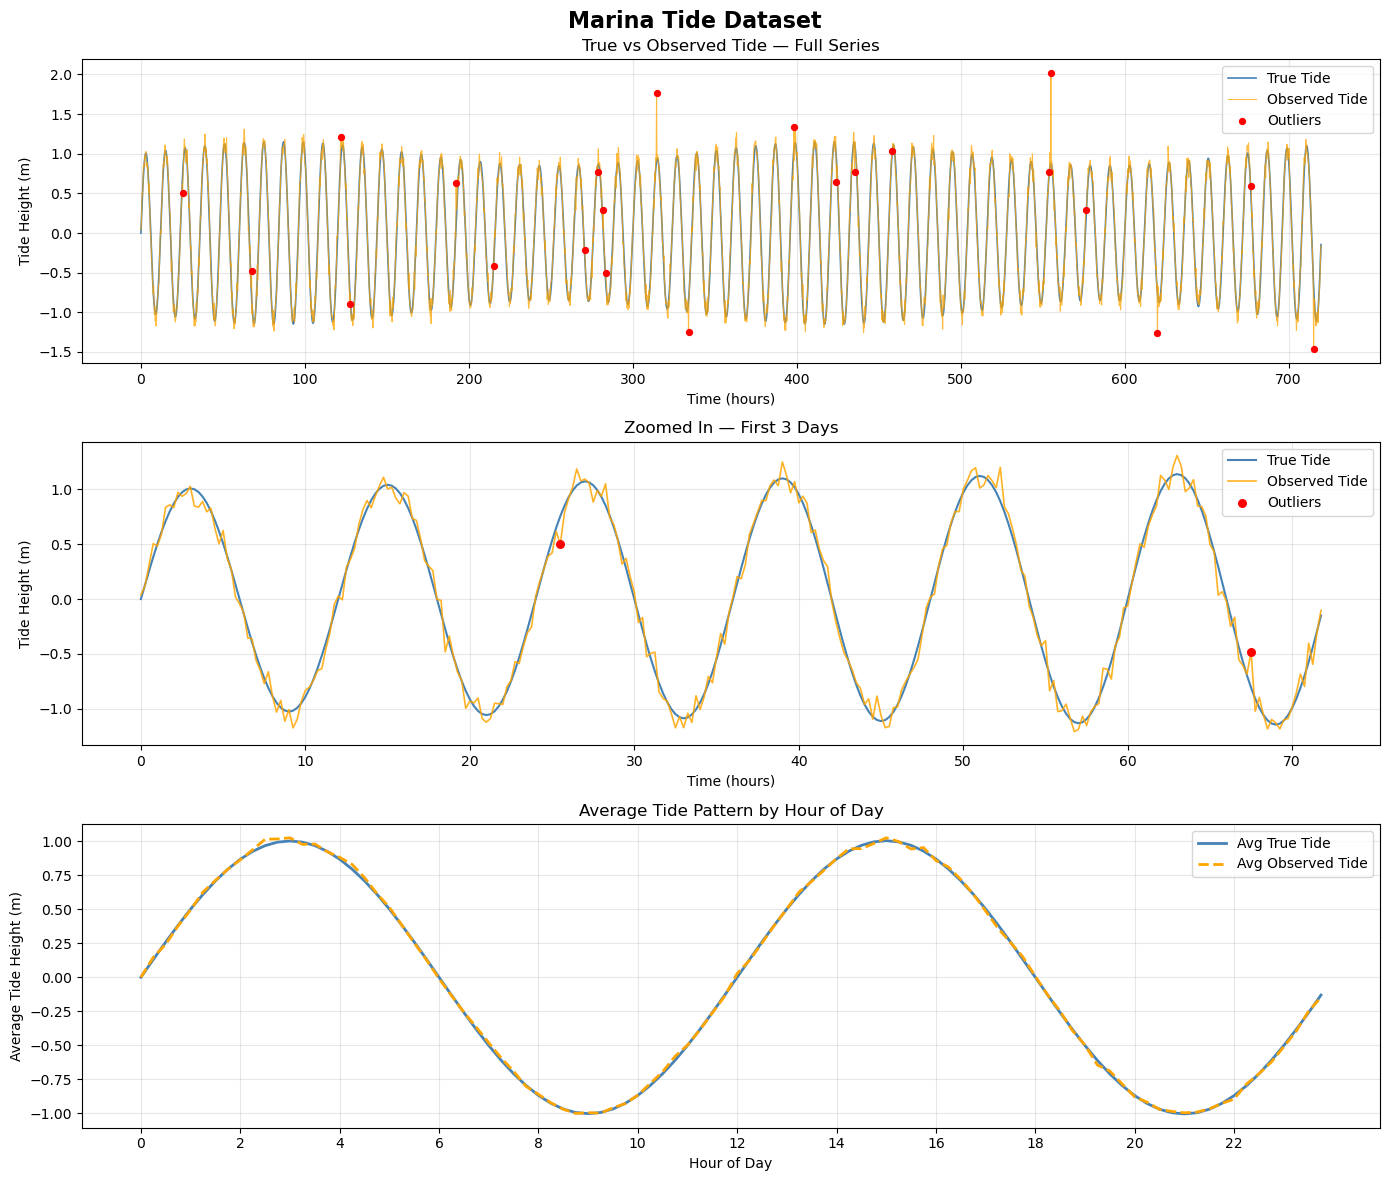

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("Marina Tide Dataset", fontsize=16, fontweight="bold")

# --- Plot 1: Full time series ---
ax = axes[0]
ax.plot(df["absolute_hour"], df["true_tide_m"], label="True Tide", linewidth=1.2, color="steelblue")
ax.plot(df["absolute_hour"], df["observed_tide_m"], label="Observed Tide", linewidth=0.8,
        color="orange", alpha=0.75)

outliers = df[df["is_outlier"]]
ax.scatter(outliers["absolute_hour"], outliers["observed_tide_m"],
           color="red", s=18, zorder=5, label="Outliers")

ax.set_xlabel("Time (hours)")
ax.set_ylabel("Tide Height (m)")
ax.set_title("True vs Observed Tide — Full Series")
ax.legend()
ax.grid(True, alpha=0.3)

# --- Plot 2: First 3 days zoomed in ---
ax = axes[1]
zoom = df[df["day"] < 3]
ax.plot(zoom["absolute_hour"], zoom["true_tide_m"], label="True Tide", linewidth=1.5, color="steelblue")
ax.plot(zoom["absolute_hour"], zoom["observed_tide_m"], label="Observed Tide", linewidth=1.2,
        color="orange", alpha=0.85)
outliers_zoom = zoom[zoom["is_outlier"]]
ax.scatter(outliers_zoom["absolute_hour"], outliers_zoom["observed_tide_m"],
           color="red", s=30, zorder=5, label="Outliers")
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Tide Height (m)")
ax.set_title("Zoomed In — First 3 Days")
ax.legend()
ax.grid(True, alpha=0.3)

# --- Plot 3: Average tide pattern by hour of day ---
ax = axes[2]
hourly_avg = df.groupby("hour_of_day")[["true_tide_m", "observed_tide_m"]].mean()
ax.plot(hourly_avg.index, hourly_avg["true_tide_m"], label="Avg True Tide", linewidth=2, color="steelblue")
ax.plot(hourly_avg.index, hourly_avg["observed_tide_m"], label="Avg Observed Tide", linewidth=2,
        color="orange", linestyle="--")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Tide Height (m)")
ax.set_title("Average Tide Pattern by Hour of Day")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

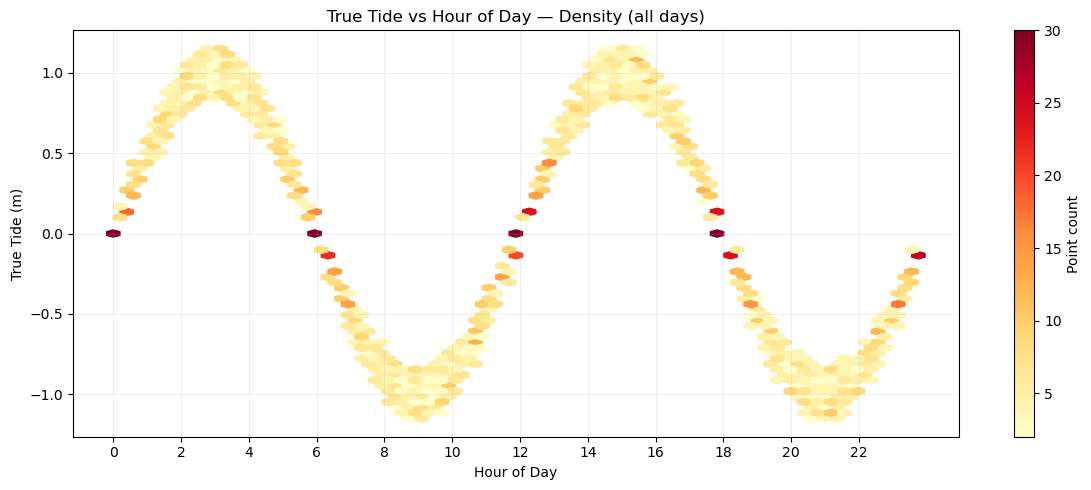

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

hb = ax.hexbin(df["hour_of_day"], df["true_tide_m"], gridsize=60, cmap="YlOrRd", mincnt=1)
fig.colorbar(hb, ax=ax, label="Point count")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("True Tide vs Hour of Day — Density (all days)")
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

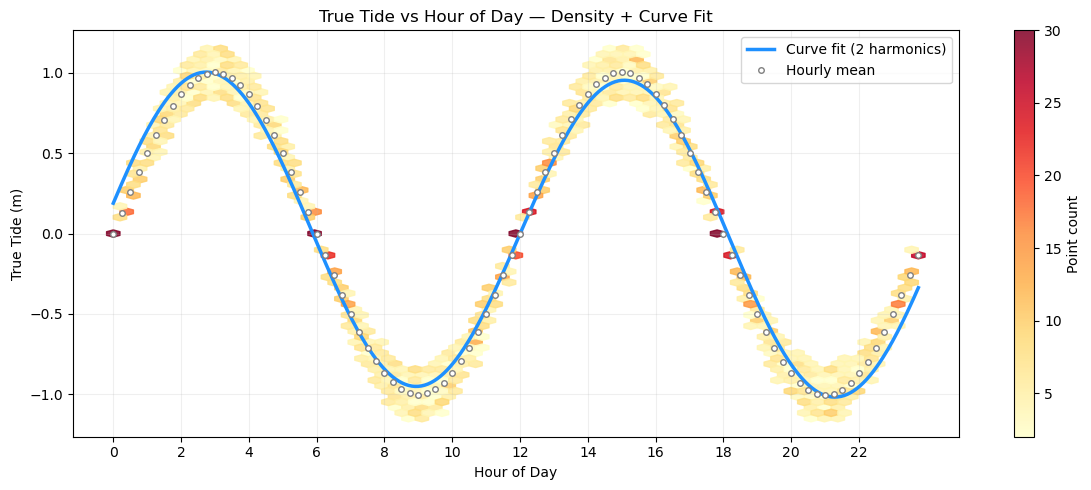

Primary harmonic  (~12.4 hr):  amplitude=0.982 m, phase=0.198 rad
Secondary harmonic (~24.8 hr): amplitude=0.042 m, phase=-0.035 rad
Mean tide level: -0.003 m


In [6]:
import numpy as np
from scipy.optimize import curve_fit

# Aggregate mean true tide per hour_of_day
hourly = df.groupby("hour_of_day")["true_tide_m"].mean().reset_index()
x_data = hourly["hour_of_day"].values
y_data = hourly["true_tide_m"].values

# Tides are semi-diurnal (~12.4 hr cycle) — fit two harmonics
def tide_model(t, A1, phi1, A2, phi2, C):
    return (A1 * np.sin(2 * np.pi * t / 12.4 + phi1) +
            A2 * np.sin(2 * np.pi * t / 24.8 + phi2) + C)

params, _ = curve_fit(tide_model, x_data, y_data, p0=[1, 0, 0.5, 0, 0], maxfev=10000)

x_smooth = np.linspace(0, 23.75, 500)
y_fit = tide_model(x_smooth, *params)

# Plot hexbin + curve fit
fig, ax = plt.subplots(figsize=(12, 5))

hb = ax.hexbin(df["hour_of_day"], df["true_tide_m"], gridsize=60, cmap="YlOrRd", mincnt=1, alpha=0.85)
fig.colorbar(hb, ax=ax, label="Point count")

ax.plot(x_smooth, y_fit, color="dodgerblue", linewidth=2.5, label="Curve fit (2 harmonics)")
ax.plot(x_data, y_data, "o", color="white", markersize=4, markeredgecolor="gray",
        linewidth=0.5, label="Hourly mean")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("True Tide vs Hour of Day — Density + Curve Fit")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

A1, phi1, A2, phi2, C = params
print(f"Primary harmonic  (~12.4 hr):  amplitude={A1:.3f} m, phase={phi1:.3f} rad")
print(f"Secondary harmonic (~24.8 hr): amplitude={A2:.3f} m, phase={phi2:.3f} rad")
print(f"Mean tide level: {C:.3f} m")

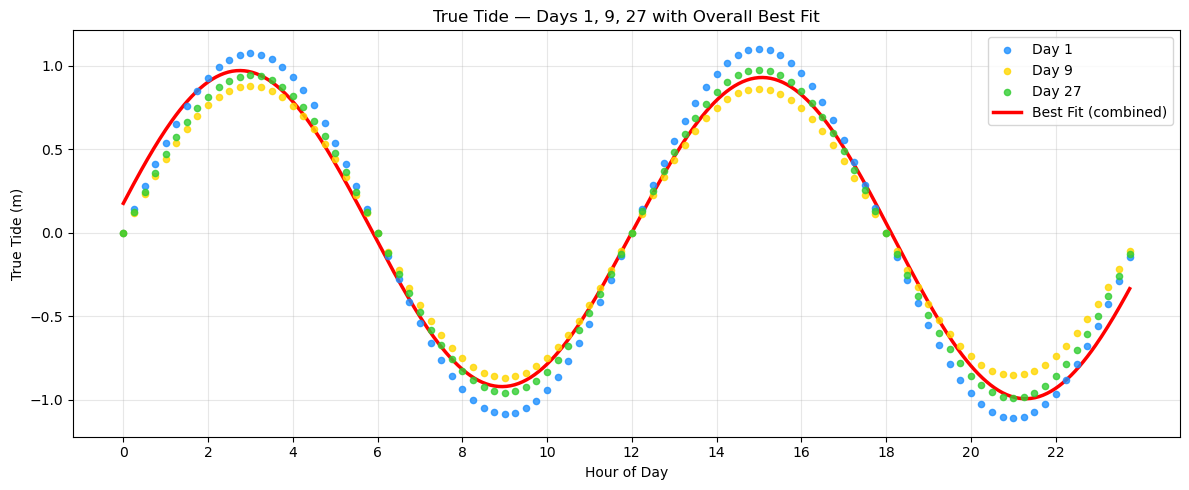

In [27]:
days = [1, 9, 27]
colors = ["dodgerblue", "gold", "limegreen"]

def tide_model(t, A1, phi1, A2, phi2, C):
    return (A1 * np.sin(2 * np.pi * t / 12.4 + phi1) +
            A2 * np.sin(2 * np.pi * t / 24.8 + phi2) + C)

combined = df[df["day"].isin(days)]
params, _ = curve_fit(tide_model, combined["hour_of_day"], combined["true_tide_m"],
                      p0=[1, 0, 0.5, 0, 0], maxfev=10000)

x_smooth = np.linspace(0, 23.75, 500)

fig, ax = plt.subplots(figsize=(12, 5))

for day, color in zip(days, colors):
    day_df = df[df["day"] == day]
    ax.scatter(day_df["hour_of_day"], day_df["true_tide_m"], s=20, color=color, alpha=0.8, zorder=3, label=f"Day {day}")

ax.plot(x_smooth, tide_model(x_smooth, *params), color="red", linewidth=2.5, label="Best Fit (combined)")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("True Tide — Days 1, 9, 27 with Overall Best Fit")
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Neural Network Curve Fit

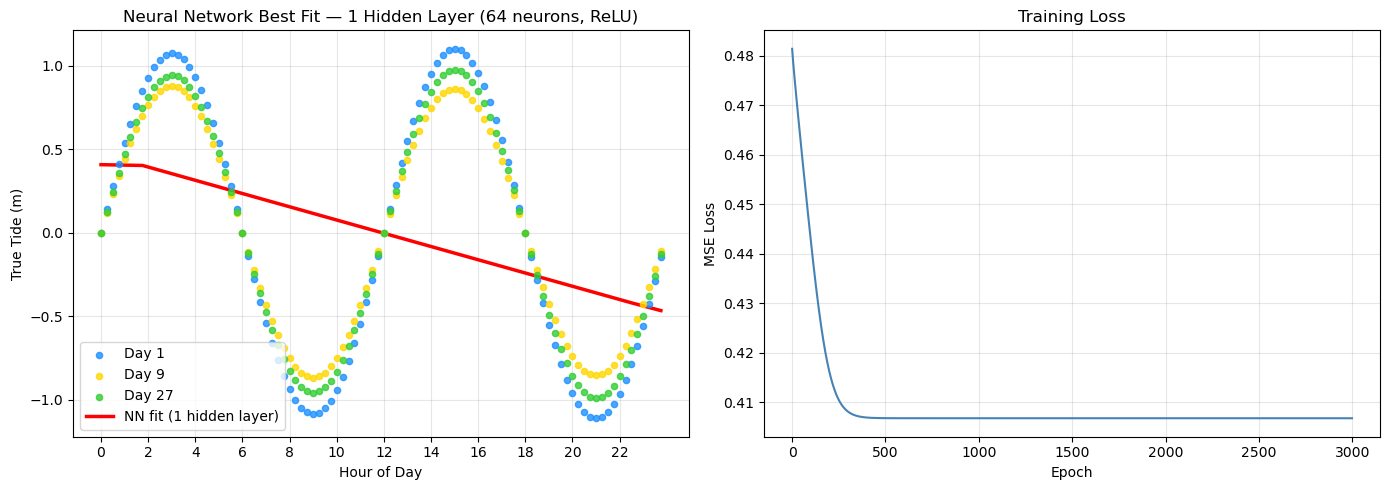

Final MSE: 0.406773


In [26]:
X = combined["hour_of_day"].values.reshape(-1, 1)  # (N, 1)
y = combined["true_tide_m"].values.reshape(-1, 1)   # (N, 1)

# Normalize input to [0, 1]
X_norm = X / 24.0

# Network: 1 -> 64 (ReLU) -> 1 (linear)
np.random.seed(42)
n_hidden = 64
lr = 0.05
epochs = 3000

W1 = np.random.randn(1, n_hidden) * 0.1
b1 = np.zeros((1, n_hidden))
W2 = np.random.randn(n_hidden, 1) * 0.1
b2 = np.zeros((1, 1))

losses = []

for epoch in range(epochs):
    # Forward pass
    z1 = X_norm @ W1 + b1       # (N, 64)
    a1 = np.maximum(0, z1)      # ReLU
    y_pred = a1 @ W2 + b2       # (N, 1)

    loss = np.mean((y_pred - y) ** 2)
    losses.append(loss)

    # Backward pass
    dL = 2 * (y_pred - y) / len(y)
    dW2 = a1.T @ dL
    db2 = dL.sum(axis=0, keepdims=True)
    da1 = dL @ W2.T
    dz1 = da1 * (z1 > 0)        # ReLU gradient
    dW1 = X_norm.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

# Predict on smooth curve
x_smooth_norm = x_smooth.reshape(-1, 1) / 24.0
a1_s = np.maximum(0, x_smooth_norm @ W1 + b1)
y_nn = a1_s @ W2 + b2

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for day, color in zip(days, colors):
    day_df = df[df["day"] == day]
    ax.scatter(day_df["hour_of_day"], day_df["true_tide_m"], s=20, color=color, alpha=0.8, zorder=3, label=f"Day {day}")
ax.plot(x_smooth, y_nn, color="red", linewidth=2.5, label="NN fit (1 hidden layer)")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("Neural Network Best Fit — 1 Hidden Layer (64 neurons, ReLU)")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(losses, color="steelblue", linewidth=1.5)
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss")
ax.set_title("Training Loss")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Final MSE: {losses[-1]:.6f}")

In [ ]:
days = [1, 9, 27]
colors = ["dodgerblue", "gold", "limegreen"]

def tide_model(t, A1, phi1, A2, phi2, C):
    return (A1 * np.sin(2 * np.pi * t / 12.4 + phi1) +
            A2 * np.sin(2 * np.pi * t / 24.8 + phi2) + C)

combined = df[df["day"].isin(days)]
params, _ = curve_fit(tide_model, combined["hour_of_day"], combined["true_tide_m"],
                      p0=[1, 0, 0.5, 0, 0], maxfev=10000)

x_smooth = np.linspace(0, 23.75, 500)

fig, ax = plt.subplots(figsize=(12, 5))

for day, color in zip(days, colors):
    day_df = df[df["day"] == day]
    ax.scatter(day_df["hour_of_day"], day_df["true_tide_m"], s=20, color=color, alpha=0.8, zorder=3, label=f"Day {day}")

ax.plot(x_smooth, tide_model(x_smooth, *params), color="red", linewidth=2.5, label="Best Fit (combined)")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("True Tide — Days 1, 9, 27 with Overall Best Fit")
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

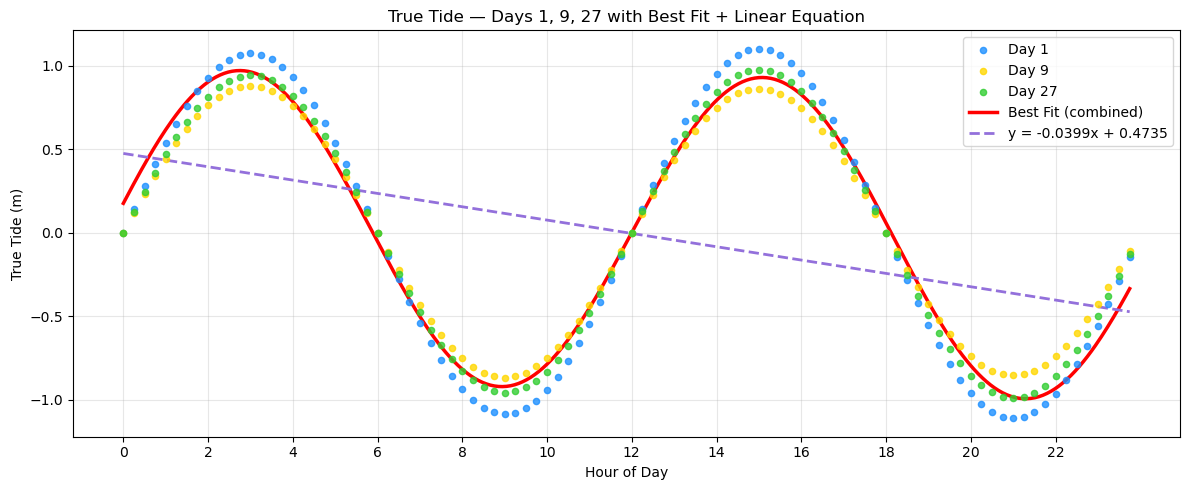

In [29]:
fig, ax = plt.subplots(figsize=(12, 5))

for day, color in zip(days, colors):
    day_df = df[df["day"] == day]
    ax.scatter(day_df["hour_of_day"], day_df["true_tide_m"], s=20, color=color, alpha=0.8, zorder=3, label=f"Day {day}")

ax.plot(x_smooth, tide_model(x_smooth, *params), color="red", linewidth=2.5, label="Best Fit (combined)")
ax.plot(x_smooth, -0.0399 * x_smooth + 0.4735, color="mediumpurple", linewidth=2, linestyle="--", label="y = -0.0399x + 0.4735")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("True Tide (m)")
ax.set_title("True Tide — Days 1, 9, 27 with Best Fit + Linear Equation")
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
tide_3col_df = df[["day", "hour_of_day", "true_tide_m"]]

output_path = Path("/Users/dmreddy/ai/Datasets/marina-tide-dataset/tide_day_hour_vs_tide.csv")
tide_3col_df.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Shape: {tide_3col_df.shape}")
tide_3col_df.head()

Saved: /Users/dmreddy/ai/Datasets/marina-tide-dataset/tide_day_hour_vs_tide.csv
Shape: (2880, 3)


,day,hour_of_day,true_tide_m
0,0,0.00,0.000000
1,0,0.25,0.130618
2,0,0.50,0.259182
3,0,0.75,0.383488
4,0,1.00,0.501402
